In [4]:
import torch, torch.nn as nn, torch.nn.functional as F
import numpy as np, random, time
import matplotlib.pyplot as plt
import pandas as pd
from torchvision.transforms import v2
import torchvision.transforms.v2.functional as TF
from torchvision.datasets import CIFAR10
from sklearn.metrics import confusion_matrix

dev = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", dev)

CLASSES = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

Device: cuda


In [5]:
DATA_SEED, SPLIT_SEED, SHIFT_SEED = 123, 0, 2024
TRAIN_SEEDS = [0, 1, 2]

# Download CIFAR-10 (automatic)
tr = CIFAR10("data", train=True,  download=True)
te = CIFAR10("data", train=False, download=True)
xall = torch.from_numpy(tr.data).permute(0,3,1,2).contiguous()
yall = torch.tensor(tr.targets)

# train_small = 500 images (50 per class)
rng = np.random.RandomState(DATA_SEED)
idx = np.concatenate([rng.choice(np.where(yall.numpy()==c)[0], 50, replace=False) for c in range(10)])
xtr, ytr = xall[idx], yall[idx]

# clean_test = original 10,000 test images
xcl = torch.from_numpy(te.data).permute(0,3,1,2).contiguous()
ycl = torch.tensor(te.targets)

# 400 train / 100 validation split
rng = np.random.RandomState(SPLIT_SEED)
tr_idx, va_idx = [], []
for c in range(10):
    ii = np.where(ytr.numpy() == c)[0]; rng.shuffle(ii)
    tr_idx += list(ii[:40]); va_idx += list(ii[40:])
x_tr, y_tr = xtr[tr_idx], ytr[tr_idx]
x_va, y_va = xtr[va_idx], ytr[va_idx]
print(len(x_tr), len(x_va), xcl.shape)


100%|██████████| 170M/170M [38:14<00:00, 74.3kB/s]


400 100 torch.Size([10000, 3, 32, 32])


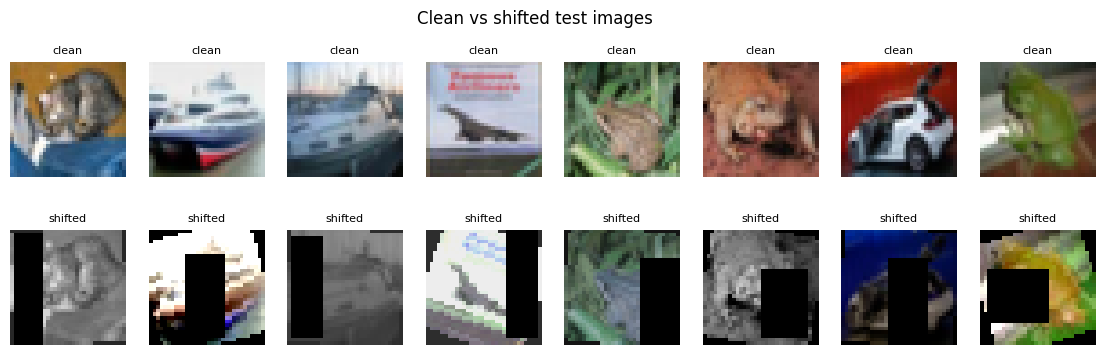

In [6]:
def hidden_corruption(img, rng):
    # TEMPORARY stand-in. Replace with the real one when your instructor sends it.
    if rng.rand() < 0.5:
        g = img.float().mean(0, keepdim=True).expand(3, -1, -1)
        return g.round().to(torch.uint8)
    return img[torch.as_tensor(rng.permutation(3))]

def make_shifted(x, seed=SHIFT_SEED):
    rng = np.random.RandomState(seed)
    out = torch.empty_like(x)
    for i in range(len(x)):
        im = TF.rotate(x[i], float(rng.uniform(-25, 25)))
        f = TF.to_dtype(im, torch.float32, scale=True)
        f = TF.adjust_brightness(f, float(rng.uniform(0.5, 1.5)))
        f = TF.adjust_contrast(f, float(rng.uniform(0.5, 1.5)))
        im = TF.to_dtype(f.clamp(0, 1), torch.uint8, scale=True).clone()
        h = int(rng.randint(8, 33)); w = min(32, int(round(256 / h)))
        top, left = rng.randint(0, 32 - h + 1), rng.randint(0, 32 - w + 1)
        im[:, top:top+h, left:left+w] = 0
        out[i] = hidden_corruption(im, rng)
    return out

xsh = make_shifted(xcl)
ysh = ycl.clone()

fig, ax = plt.subplots(2, 8, figsize=(14,4))
for i in range(8):
    ax[0,i].imshow(xcl[i].permute(1,2,0)); ax[0,i].axis('off'); ax[0,i].set_title("clean", fontsize=8)
    ax[1,i].imshow(xsh[i].permute(1,2,0)); ax[1,i].axis('off'); ax[1,i].set_title("shifted", fontsize=8)
plt.suptitle("Clean vs shifted test images"); plt.show()

In [7]:
class Inception(nn.Module):
    def __init__(self, cin, c1, c3r, c3, c5r, c5, cp):
        super().__init__()
        def cbr(i, o, k):
            return nn.Sequential(nn.Conv2d(i, o, k, padding=k//2, bias=False), nn.BatchNorm2d(o), nn.ReLU(True))
        self.b1 = cbr(cin, c1, 1)                                         # 1x1 branch
        self.b3 = nn.Sequential(cbr(cin, c3r, 1), cbr(c3r, c3, 3))        # 1x1 reduce -> 3x3
        self.b5 = nn.Sequential(cbr(cin, c5r, 1), cbr(c5r, c5, 5))        # 1x1 reduce -> 5x5
        self.bp = nn.Sequential(nn.MaxPool2d(3, 1, 1), cbr(cin, cp, 1))   # pool -> 1x1
    def forward(self, x):
        return torch.cat([self.b1(x), self.b3(x), self.b5(x), self.bp(x)], 1)

class Net(nn.Module):
    def __init__(self, p_drop=0.5):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 32, 3, padding=1, bias=False), nn.BatchNorm2d(32), nn.ReLU(True))
        self.i1 = Inception(32, 16, 16, 24, 4, 8, 8)         # outputs 56 channels
        self.i2 = Inception(56, 32, 32, 64, 8, 16, 16)       # outputs 128
        self.i3 = Inception(128, 64, 64, 128, 16, 32, 32)    # outputs 256
        self.pool = nn.MaxPool2d(2)
        self.drop = nn.Dropout(p_drop)
        self.fc = nn.Linear(256, 10)
    def forward(self, x):
        x = self.stem(x)
        x = self.pool(self.i1(x))
        x = self.pool(self.i2(x))
        x = self.i3(x)
        x = F.adaptive_avg_pool2d(x, 1).flatten(1)
        return self.fc(self.drop(x))

n_params = sum(p.numel() for p in Net().parameters() if p.requires_grad)
print("Trainable parameters:", n_params, "| limit 1,000,000 ->", "OK" if n_params <= 1_000_000 else "TOO MANY")

Trainable parameters: 145938 | limit 1,000,000 -> OK


In [9]:
MEAN = torch.tensor([0.4914, 0.4822, 0.4465]).view(1,3,1,1)
STD  = torch.tensor([0.247, 0.243, 0.261]).view(1,3,1,1)

class RandApply:                      # applies a transform with probability p
    def __init__(self, t, p): self.t, self.p = t, p
    def __call__(self, x): return self.t(x) if random.random() < self.p else x

class GaussNoise:
    def __init__(self, std=(0.0, 0.08)): self.std = std
    def __call__(self, x): return (x + torch.randn_like(x) * random.uniform(*self.std)).clamp(0, 1)

class ChannelShuffle:
    def __call__(self, x): return x[torch.randperm(3)]

def make_tf(geo=0, photo=0, cutout=0):
    t = [v2.ToDtype(torch.float32, scale=True)]          # uint8 -> float in [0,1]
    if geo:
        t += [v2.RandomCrop(32, padding=4, padding_mode='reflect'),
              v2.RandomHorizontalFlip(),
              v2.RandomAffine(degrees=25, translate=(0.1, 0.1), scale=(0.9, 1.1))]
    if photo:
        t += [v2.ColorJitter(0.4, 0.4, 0.4, 0.05),
              RandApply(v2.GaussianBlur(3, sigma=(0.1, 1.5)), 0.3),
              RandApply(GaussNoise(), 0.5),
              v2.RandomGrayscale(p=0.2),
              RandApply(ChannelShuffle(), 0.2)]
    t += [v2.Normalize(MEAN.flatten().tolist(), STD.flatten().tolist())]
    if cutout:
        t += [v2.RandomErasing(p=0.7, scale=(0.05, 0.3), ratio=(0.3, 3.3), value=0)]
    return v2.Compose(t)

class DS(torch.utils.data.Dataset):
    def __init__(self, x, y, tf): self.x, self.y, self.tf = x, y, tf
    def __len__(self): return len(self.x)
    def __getitem__(self, i): return self.tf(self.x[i]), self.y[i]   # augmentation happens here, fresh every epoch

def loader(x, y, tf, shuffle, bs=64):
    return torch.utils.data.DataLoader(DS(x, y, tf), batch_size=bs, shuffle=shuffle)

def prep(x):   # for validation/test: NO augmentation, only scale + normalize
    return ((x.float() / 255) - MEAN) / STD


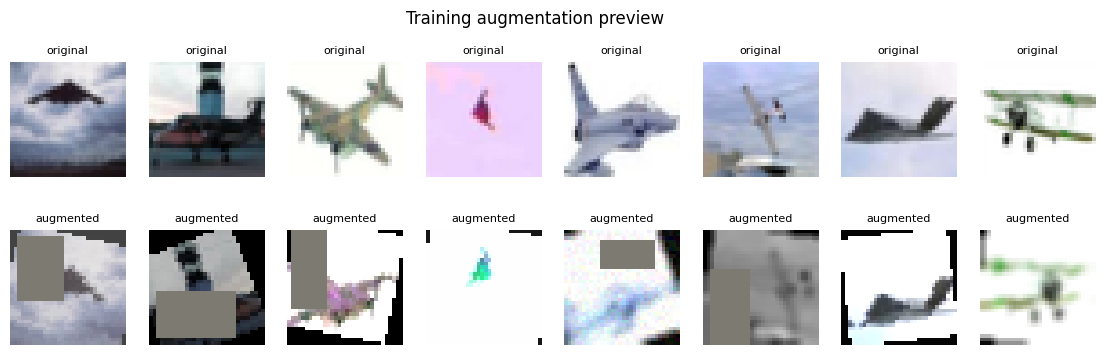

In [10]:
tf_preview = make_tf(1, 1, 1)
fig, ax = plt.subplots(2, 8, figsize=(14,4))
for i in range(8):
    ax[0,i].imshow(x_tr[i].permute(1,2,0)); ax[0,i].axis('off'); ax[0,i].set_title("original", fontsize=8)
    a = tf_preview(x_tr[i]) * STD[0] + MEAN[0]
    ax[1,i].imshow(a.clamp(0,1).permute(1,2,0)); ax[1,i].axis('off'); ax[1,i].set_title("augmented", fontsize=8)
plt.suptitle("Training augmentation preview"); plt.show()

In [14]:
@torch.no_grad()
def evaluate(model, x, y, bs=500):
    model.eval(); preds = []
    for i in range(0, len(x), bs):
        preds.append(model(prep(x[i:i+bs]).to(dev)).argmax(1).cpu())
    p = torch.cat(preds)
    return (p == y).float().mean().item(), p

def mixup_batch(x, y, alpha=0.4):
    lam = np.random.beta(alpha, alpha)
    idx = torch.randperm(x.size(0), device=x.device)
    return lam * x + (1 - lam) * x[idx], y, y[idx], lam
def train(cfg, seed, epochs=60, lr=1e-3, wd=5e-4, ls_val=0.1, p_drop=0.3, patience=20, bs=64):
    set_seed(seed)
    model = Net(p_drop).to(dev)
    tl = loader(x_tr, y_tr, make_tf(cfg.get('geo',0), cfg.get('photo',0), cfg.get('cutout',0)), True, bs)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * len(tl))
    ls = ls_val if cfg.get('ls', 0) else 0.0
    hist = {'train_loss': [], 'train_acc': [], 'val_acc': []}
    best, best_state, bad = 0, None, 0
    for ep in range(epochs):
        model.train(); loss_sum = cor = n = 0
        for xb, yb in tl:
            xb, yb = xb.to(dev), yb.to(dev)
            if cfg.get('mixup', 0):
                xb, ya, yb2, lam = mixup_batch(xb, yb)
                out = model(xb)
                loss = lam * F.cross_entropy(out, ya, label_smoothing=ls) + (1 - lam) * F.cross_entropy(out, yb2, label_smoothing=ls)
            else:
                out = model(xb)
                loss = F.cross_entropy(out, yb, label_smoothing=ls)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
            loss_sum += loss.item() * len(yb); cor += (out.argmax(1) == yb).sum().item(); n += len(yb)
        va, _ = evaluate(model, x_va, y_va)               # validation only, never the test sets
        hist['train_loss'].append(loss_sum / n); hist['train_acc'].append(cor / n); hist['val_acc'].append(va)
        if va > best:
            best, bad = va, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break                     # early stopping on validation accuracy
    model.load_state_dict(best_state)
    return model, hist, best

In [12]:
t0 = time.time()
m, h, best = train({}, seed=0)          # {} = no augmentation (this is your Part A baseline)
cl, _ = evaluate(m, xcl, ycl)
sh, _ = evaluate(m, xsh, ysh)
print(f"Train {h['train_acc'][-1]:.3f} | Val {best:.3f} | Clean test {cl:.3f} | Shifted test {sh:.3f} | time {time.time()-t0:.0f}s")

Train 1.000 | Val 0.590 | Clean test 0.468 | Shifted test 0.176 | time 12s


In [13]:
full_cfg = dict(geo=1, photo=1, cutout=1, mixup=1, ls=1)

tuning = []
for name, grid in [('lr', [1e-3, 2e-3, 5e-3]),
                   ('wd', [1e-4, 5e-4, 5e-3]),
                   ('p_drop', [0.3, 0.5, 0.7])]:
    for v in grid:
        vals = [train(full_cfg, seed=s, **{name: v})[2] for s in [0, 1]]   # 2 seeds to reduce noise
        tuning.append((name, v, np.mean(vals)))
        print(f"{name}={v}: mean val acc = {np.mean(vals):.3f}")

lr=0.001: mean val acc = 0.475
lr=0.002: mean val acc = 0.465
lr=0.005: mean val acc = 0.475
wd=0.0001: mean val acc = 0.480
wd=0.0005: mean val acc = 0.480
wd=0.005: mean val acc = 0.480
p_drop=0.3: mean val acc = 0.510
p_drop=0.5: mean val acc = 0.470
p_drop=0.7: mean val acc = 0.455


In [15]:
configs = {
 'No augmentation':             {},
 'Geometric only':              dict(geo=1),
 'Photometric only':            dict(photo=1),
 'Geometric + photometric':     dict(geo=1, photo=1),
 '+ Cutout / Random Erasing':   dict(geo=1, photo=1, cutout=1),
 '+ Mixup + label smoothing':   dict(geo=1, photo=1, cutout=1, mixup=1, ls=1),
}
results, hists, models = {}, {}, {}

for name, cfg in configs.items():
    rows = []; hists[name] = []; models[name] = {}
    for s in TRAIN_SEEDS:
        m, h, best = train(cfg, s)
        cl, _ = evaluate(m, xcl, ycl); sh, _ = evaluate(m, xsh, ysh)
        rows.append((h['train_acc'][-1], best, cl, sh))
        hists[name].append(h); models[name][s] = m
        print(f"{name} | seed {s} | val {best:.3f} clean {cl:.3f} shifted {sh:.3f}")
    results[name] = np.array(rows) * 100

table = pd.DataFrame({
    n: [f"{r[:,1].mean():.1f} ± {r[:,1].std():.1f}",
        f"{r[:,2].mean():.1f} ± {r[:,2].std():.1f}",
        f"{r[:,3].mean():.1f} ± {r[:,3].std():.1f}"]
    for n, r in results.items()}, index=['Val Acc', 'Clean Test', 'Shifted Test']).T
table

No augmentation | seed 0 | val 0.550 clean 0.433 shifted 0.171
No augmentation | seed 1 | val 0.550 clean 0.433 shifted 0.144
No augmentation | seed 2 | val 0.520 clean 0.437 shifted 0.167
Geometric only | seed 0 | val 0.490 clean 0.428 shifted 0.192
Geometric only | seed 1 | val 0.470 clean 0.377 shifted 0.186
Geometric only | seed 2 | val 0.460 clean 0.415 shifted 0.197
Photometric only | seed 0 | val 0.550 clean 0.468 shifted 0.165
Photometric only | seed 1 | val 0.530 clean 0.456 shifted 0.160
Photometric only | seed 2 | val 0.580 clean 0.467 shifted 0.176
Geometric + photometric | seed 0 | val 0.520 clean 0.398 shifted 0.198
Geometric + photometric | seed 1 | val 0.510 clean 0.407 shifted 0.186
Geometric + photometric | seed 2 | val 0.430 clean 0.322 shifted 0.149
+ Cutout / Random Erasing | seed 0 | val 0.440 clean 0.377 shifted 0.195
+ Cutout / Random Erasing | seed 1 | val 0.460 clean 0.350 shifted 0.156
+ Cutout / Random Erasing | seed 2 | val 0.470 clean 0.376 shifted 0.163
+

,Val Acc,Clean Test,Shifted Test
No augmentation,54.0 ± 1.4,43.4 ± 0.2,16.1 ± 1.2
Geometric only,47.3 ± 1.2,40.7 ± 2.2,19.2 ± 0.4
Photometric only,55.3 ± 2.1,46.4 ± 0.5,16.7 ± 0.7
Geometric + photometric,48.7 ± 4.0,37.6 ± 3.8,17.8 ± 2.1
+ Cutout / Random Erasing,45.7 ± 1.2,36.8 ± 1.3,17.1 ± 1.7
+ Mixup + label smoothing,48.7 ± 1.7,38.7 ± 1.2,16.9 ± 1.9


In [16]:
final_name = max(results, key=lambda n: results[n][:,1].mean())
print("Final model config:", final_name)
r = results[final_name]
print(f"FINAL shifted test = {r[:,3].mean():.2f} ± {r[:,3].std():.2f} | clean = {r[:,2].mean():.2f} ± {r[:,2].std():.2f}")


Final model config: Photometric only
FINAL shifted test = 16.71 ± 0.66 | clean = 46.38 ± 0.52


In [17]:
def corrupt(x, seed, rot=True, bc=True, occ=True):
    rng = np.random.RandomState(seed)
    out = x.clone()
    for i in range(len(x)):
        im = x[i].clone()
        if rot:
            im = TF.rotate(im, float(rng.uniform(-25, 25)))
        if bc:
            f = TF.to_dtype(im, torch.float32, scale=True)
            f = TF.adjust_brightness(f, float(rng.uniform(0.5, 1.5)))
            f = TF.adjust_contrast(f, float(rng.uniform(0.5, 1.5)))
            im = TF.to_dtype(f.clamp(0, 1), torch.uint8, scale=True).clone()
        if occ:
            h = int(rng.randint(8, 33)); w = min(32, int(round(256 / h)))
            top, left = rng.randint(0, 32 - h + 1), rng.randint(0, 32 - w + 1)
            im[:, top:top+h, left:left+w] = 0
        out[i] = im
    return out

VAL_SHIFT_SEED = 777   # different from SHIFT_SEED; document it in your report
xva_sh = torch.cat([corrupt(x_va, VAL_SHIFT_SEED + k) for k in range(5)])   # 500 corrupted val images
yva_sh = y_va.repeat(5)
print(xva_sh.shape)

torch.Size([500, 3, 32, 32])


In [18]:
rows = []
for mname in ['No augmentation', '+ Cutout / Random Erasing']:
    m = models[mname][0]
    r = {'model': mname, 'clean val': evaluate(m, x_va, y_va)[0] * 100}
    for cname, kw in [('rotation only', dict(bc=False, occ=False)),
                      ('brightness/contrast only', dict(rot=False, occ=False)),
                      ('occlusion only', dict(rot=False, bc=False)),
                      ('all three', {})]:
        xs = torch.cat([corrupt(x_va, VAL_SHIFT_SEED + k, **kw) for k in range(5)])
        r[cname] = evaluate(m, xs, yva_sh)[0] * 100
    rows.append(r)
pd.DataFrame(rows).round(1)

,model,clean val,rotation only,brightness/contrast only,occlusion only,all three
0,No augmentation,55.0,41.0,40.2,34.2,23.8
1,+ Cutout / Random Erasing,44.0,39.0,36.0,33.2,24.6


In [20]:
def make_tf(geo=0, photo=0, cutout=0):
    t = [v2.ToDtype(torch.float32, scale=True)]
    if geo:
        t += [v2.RandomCrop(32, padding=4, padding_mode='reflect'),
              v2.RandomHorizontalFlip(),
              v2.RandomAffine(degrees=25, translate=(0.1, 0.1), scale=(0.9, 1.1))]
    if photo:
        t += [v2.ColorJitter(0.5, 0.5, 0.4, 0.05),
              RandApply(v2.GaussianBlur(3, sigma=(0.1, 1.5)), 0.3),
              RandApply(GaussNoise(), 0.5),
              v2.RandomGrayscale(p=0.2),
              RandApply(ChannelShuffle(), 0.2)]
    if cutout:   # BEFORE normalize, black fill, to match black test occlusion
        t += [v2.RandomErasing(p=0.7, scale=(0.05, 0.3), ratio=(0.3, 3.3), value=0)]
    t += [v2.Normalize(MEAN.flatten().tolist(), STD.flatten().tolist())]
    return v2.Compose(t)

def train(cfg, seed, epochs=60, lr=1e-3, wd=5e-4, ls_val=0.1, p_drop=0.3, patience=25, bs=32):
    set_seed(seed)
    model = Net(p_drop).to(dev)
    tl = loader(x_tr, y_tr, make_tf(cfg.get('geo',0), cfg.get('photo',0), cfg.get('cutout',0)), True, bs)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * len(tl))
    ls = ls_val if cfg.get('ls', 0) else 0.0
    hist = {'train_loss': [], 'train_acc': [], 'val_acc': [], 'val_sh': []}
    best, best_state, best_ep, bad = -1, None, 0, 0
    for ep in range(epochs):
        model.train(); loss_sum = cor = n = 0
        for xb, yb in tl:
            xb, yb = xb.to(dev), yb.to(dev)
            if cfg.get('mixup', 0):
                xb, ya, yb2, lam = mixup_batch(xb, yb)
                out = model(xb)
                loss = lam * F.cross_entropy(out, ya, label_smoothing=ls) + (1 - lam) * F.cross_entropy(out, yb2, label_smoothing=ls)
            else:
                out = model(xb)
                loss = F.cross_entropy(out, yb, label_smoothing=ls)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
            loss_sum += loss.item() * len(yb); cor += (out.argmax(1) == yb).sum().item(); n += len(yb)
        va, _ = evaluate(model, x_va, y_va)           # clean validation
        vs, _ = evaluate(model, xva_sh, yva_sh)       # corrupted validation
        hist['train_loss'].append(loss_sum / n); hist['train_acc'].append(cor / n)
        hist['val_acc'].append(va); hist['val_sh'].append(vs)
        score = (va + vs) / 2                         # robust validation score
        if score > best:
            best, best_ep, bad = score, ep, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    hist['best_ep'] = best_ep
    model.load_state_dict(best_state)
    return model, hist, best          # best = robust validation score

In [22]:
configs = {
 'No augmentation':             {},
 'Geometric only':              dict(geo=1),
 'Photometric only':            dict(photo=1),
 'Geometric + photometric':     dict(geo=1, photo=1),
 '+ Cutout / Random Erasing':   dict(geo=1, photo=1, cutout=1),
 '+ Mixup + label smoothing':   dict(geo=1, photo=1, cutout=1, mixup=1, ls=1),
}
results, hists, models = {}, {}, {}

for name, cfg in configs.items():
    rows = []; hists[name] = []; models[name] = {}
    for s in TRAIN_SEEDS:
        m, h, best = train(cfg, s)
        cl, _ = evaluate(m, xcl, ycl); sh, _ = evaluate(m, xsh, ysh)
        rows.append((h['train_acc'][-1], h['val_acc'][h['best_ep']], cl, sh, best))
        hists[name].append(h); models[name][s] = m
        print(f"{name} | seed {s} | val {rows[-1][1]:.3f} robust-val {best:.3f} clean {cl:.3f} shifted {sh:.3f}")
    results[name] = np.array(rows) * 100

table = pd.DataFrame({
    n: [f"{r[:,1].mean():.1f} ± {r[:,1].std():.1f}",
        f"{r[:,4].mean():.1f} ± {r[:,4].std():.1f}",
        f"{r[:,2].mean():.1f} ± {r[:,2].std():.1f}",
        f"{r[:,3].mean():.1f} ± {r[:,3].std():.1f}"]
    for n, r in results.items()}, index=['Val Acc', 'Robust Val', 'Clean Test', 'Shifted Test']).T
display(table)

final_name = max(results, key=lambda n: results[n][:,4].mean())   # chosen by VALIDATION only
r = results[final_name]
print("Final model config:", final_name)
print(f"FINAL shifted test = {r[:,3].mean():.2f} ± {r[:,3].std():.2f} | clean = {r[:,2].mean():.2f} ± {r[:,2].std():.2f}")

No augmentation | seed 0 | val 0.570 robust-val 0.394 clean 0.460 shifted 0.165
No augmentation | seed 1 | val 0.560 robust-val 0.376 clean 0.452 shifted 0.153
No augmentation | seed 2 | val 0.550 robust-val 0.422 clean 0.431 shifted 0.170
Geometric only | seed 0 | val 0.500 robust-val 0.403 clean 0.436 shifted 0.195
Geometric only | seed 1 | val 0.500 robust-val 0.396 clean 0.412 shifted 0.190
Geometric only | seed 2 | val 0.520 robust-val 0.414 clean 0.430 shifted 0.196
Photometric only | seed 0 | val 0.490 robust-val 0.351 clean 0.394 shifted 0.159
Photometric only | seed 1 | val 0.600 robust-val 0.391 clean 0.458 shifted 0.161
Photometric only | seed 2 | val 0.570 robust-val 0.388 clean 0.477 shifted 0.170
Geometric + photometric | seed 0 | val 0.510 robust-val 0.396 clean 0.431 shifted 0.208
Geometric + photometric | seed 1 | val 0.510 robust-val 0.411 clean 0.433 shifted 0.217
Geometric + photometric | seed 2 | val 0.540 robust-val 0.428 clean 0.424 shifted 0.202
+ Cutout / Rando

,Val Acc,Robust Val,Clean Test,Shifted Test
No augmentation,56.0 ± 0.8,39.7 ± 1.9,44.7 ± 1.2,16.3 ± 0.7
Geometric only,50.7 ± 0.9,40.4 ± 0.7,42.6 ± 1.0,19.3 ± 0.3
Photometric only,55.3 ± 4.6,37.7 ± 1.8,44.3 ± 3.6,16.4 ± 0.5
Geometric + photometric,52.0 ± 1.4,41.2 ± 1.3,42.9 ± 0.4,20.9 ± 0.6
+ Cutout / Random Erasing,46.3 ± 1.7,42.4 ± 1.0,39.9 ± 0.5,27.0 ± 0.4
+ Mixup + label smoothing,47.3 ± 1.9,42.0 ± 1.3,38.5 ± 1.2,25.3 ± 0.6


Final model config: + Cutout / Random Erasing
FINAL shifted test = 27.01 ± 0.45 | clean = 39.89 ± 0.49


BASELINE (3 seeds)  Train 100.0±0.0 | Val 56.0±0.8 | Clean test 44.7±1.2 | Shifted test 16.3±0.7


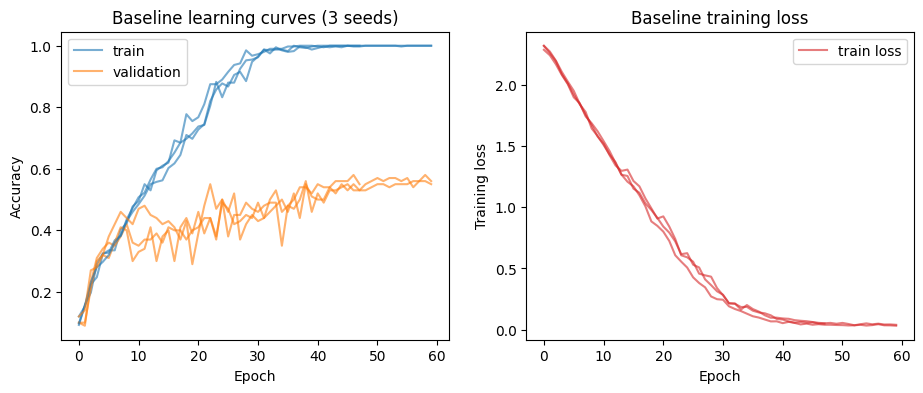

In [23]:
r = results['No augmentation']
print(f"BASELINE (3 seeds)  Train {r[:,0].mean():.1f}±{r[:,0].std():.1f} | Val {r[:,1].mean():.1f}±{r[:,1].std():.1f} | "
      f"Clean test {r[:,2].mean():.1f}±{r[:,2].std():.1f} | Shifted test {r[:,3].mean():.1f}±{r[:,3].std():.1f}")

fig, ax = plt.subplots(1, 2, figsize=(11,4))
for k, h in enumerate(hists['No augmentation']):
    ax[0].plot(h['train_acc'], color='tab:blue', alpha=.6, label='train' if k==0 else None)
    ax[0].plot(h['val_acc'],   color='tab:orange', alpha=.6, label='validation' if k==0 else None)
    ax[1].plot(h['train_loss'], color='tab:red', alpha=.6, label='train loss' if k==0 else None)
ax[0].set(xlabel='Epoch', ylabel='Accuracy', title='Baseline learning curves (3 seeds)'); ax[0].legend()
ax[1].set(xlabel='Epoch', ylabel='Training loss', title='Baseline training loss'); ax[1].legend()
plt.show()

In [24]:
rows = []
for mname in ['No augmentation', 'Geometric only', 'Geometric + photometric', final_name]:
    m = models[mname][0]
    r = {'model': mname, 'clean val': evaluate(m, x_va, y_va)[0] * 100}
    for cname, kw in [('rotation only', dict(bc=False, occ=False)),
                      ('brightness/contrast only', dict(rot=False, occ=False)),
                      ('occlusion only', dict(rot=False, bc=False)),
                      ('all three', {})]:
        xs = torch.cat([corrupt(x_va, VAL_SHIFT_SEED + k, **kw) for k in range(5)])
        r[cname] = evaluate(m, xs, yva_sh)[0] * 100
    rows.append(r)
pd.DataFrame(rows).round(1)

,model,clean val,rotation only,brightness/contrast only,occlusion only,all three
0,No augmentation,57.0,43.4,42.4,32.0,21.8
1,Geometric only,50.0,47.8,36.2,38.4,30.6
2,Geometric + photometric,51.0,47.2,44.4,34.4,28.2
3,+ Cutout / Random Erasing,44.0,42.2,39.6,40.2,38.2


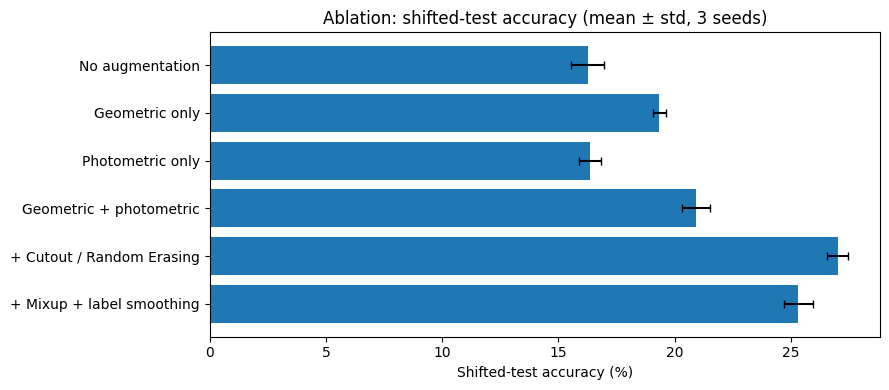

In [25]:
names = list(results.keys())
means = [results[n][:,3].mean() for n in names]; stds = [results[n][:,3].std() for n in names]
plt.figure(figsize=(9,4)); plt.barh(names, means, xerr=stds, color='tab:blue', capsize=3)
plt.xlabel('Shifted-test accuracy (%)'); plt.title('Ablation: shifted-test accuracy (mean ± std, 3 seeds)')
plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

airplane      28.0
automobile    41.0
bird           6.4
cat           14.8
deer          18.0
dog           38.3
frog          26.8
horse         24.5
ship          38.4
truck         39.5
dtype: float64


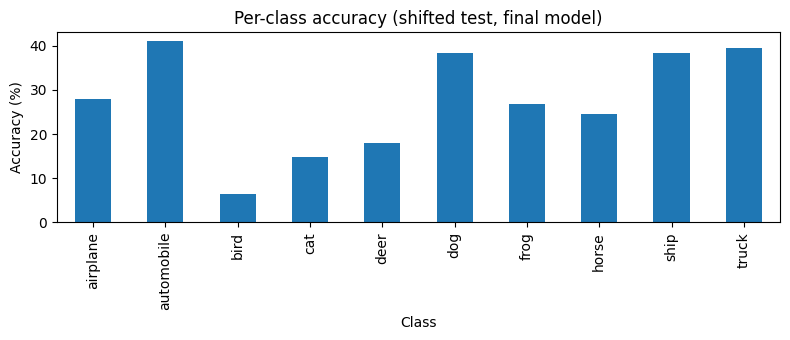

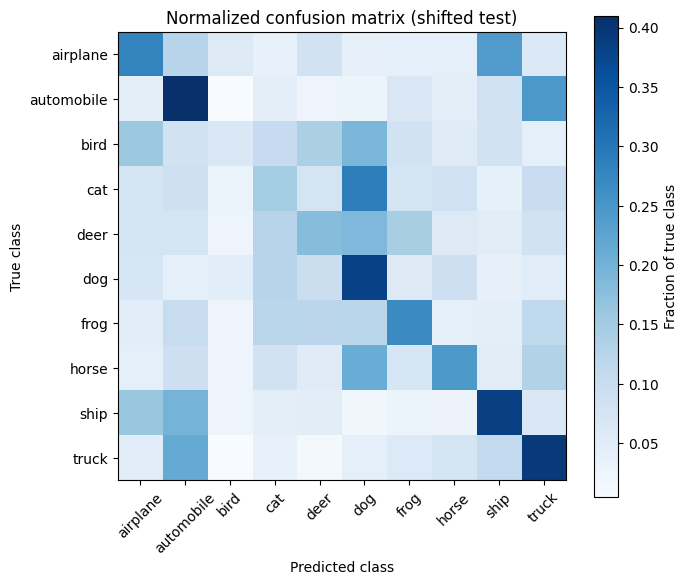

Most confused pairs (true -> predicted):
  cat -> dog: 0.29
  automobile -> truck: 0.25
  airplane -> ship: 0.24
  truck -> automobile: 0.21
  horse -> dog: 0.21
  ship -> automobile: 0.20


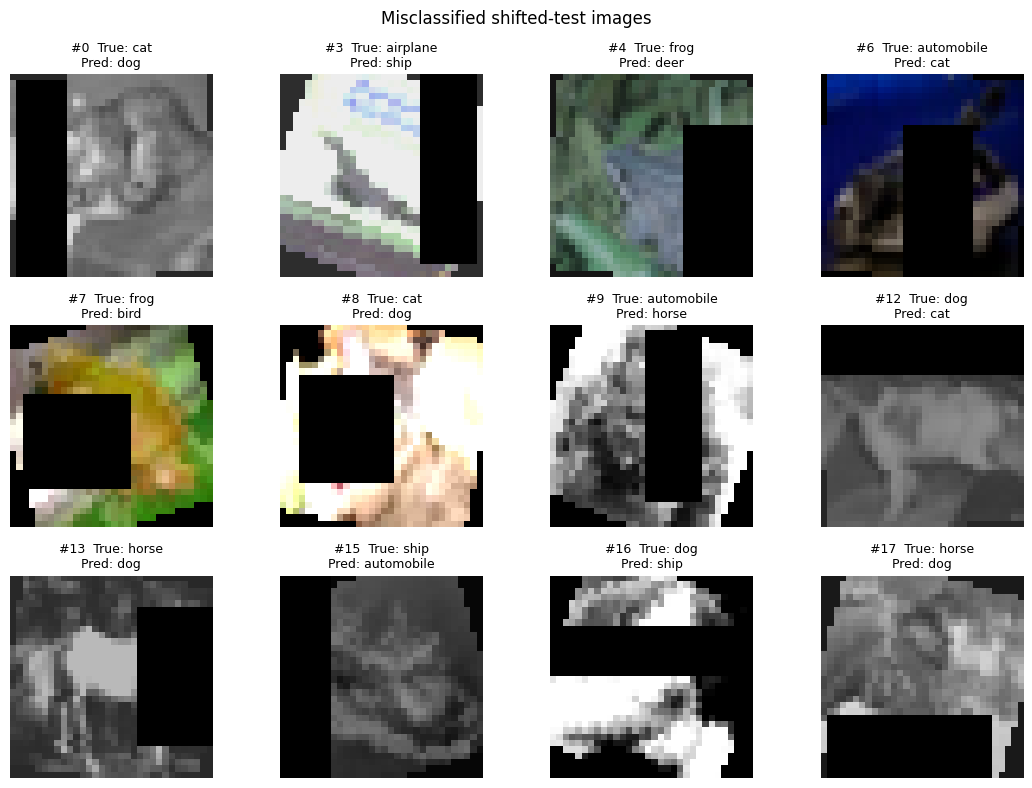

In [26]:
model = models[final_name][0]
acc, pred = evaluate(model, xsh, ysh)
cm = confusion_matrix(ysh, pred, normalize='true')

per_class = pd.Series(cm.diagonal() * 100, index=CLASSES).round(1)
print(per_class)
per_class.plot(kind='bar', figsize=(8,3.5), title='Per-class accuracy (shifted test, final model)', ylabel='Accuracy (%)', xlabel='Class')
plt.tight_layout(); plt.show()

plt.figure(figsize=(7,6)); plt.imshow(cm, cmap='Blues'); plt.colorbar(label='Fraction of true class')
plt.xticks(range(10), CLASSES, rotation=45); plt.yticks(range(10), CLASSES)
plt.xlabel('Predicted class'); plt.ylabel('True class'); plt.title('Normalized confusion matrix (shifted test)')
plt.tight_layout(); plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
print("Most confused pairs (true -> predicted):")
for i, j in zip(*np.unravel_index(np.argsort(off, axis=None)[::-1][:6], off.shape)):
    print(f"  {CLASSES[i]} -> {CLASSES[j]}: {off[i,j]:.2f}")

wrong = np.where(pred.numpy() != ysh.numpy())[0][:12]
fig, ax = plt.subplots(3, 4, figsize=(11, 8))
for a, i in zip(ax.flat, wrong):
    a.imshow(xsh[i].permute(1,2,0)); a.axis('off')
    a.set_title(f"#{i}  True: {CLASSES[ysh[i]]}\nPred: {CLASSES[pred[i]]}", fontsize=9)
plt.suptitle("Misclassified shifted-test images"); plt.tight_layout(); plt.show()

In [27]:
def apply_hidden(x, seed=SHIFT_SEED + 1):
    rng = np.random.RandomState(seed)
    return torch.stack([hidden_corruption(x[i], rng) for i in range(len(x))])

def gray(x): return x.float().mean(1, keepdim=True).expand(-1,3,-1,-1).round().to(torch.uint8)
def swap(x): return x[:, [2,1,0]]

xh = apply_hidden(xcl)
rows = []
for mname in ['No augmentation', 'Geometric only', 'Geometric + photometric', final_name]:
    m = models[mname][0]
    rows.append({'model': mname,
                 'clean': evaluate(m, xcl, ycl)[0]*100,
                 'hidden corruption only': evaluate(m, xh, ycl)[0]*100,
                 'grayscale only': evaluate(m, gray(xcl), ycl)[0]*100,
                 'channel swap only': evaluate(m, swap(xcl), ycl)[0]*100})
pd.DataFrame(rows).round(1)

,model,clean,hidden corruption only,grayscale only,channel swap only
0,No augmentation,46.0,35.6,39.0,27.0
1,Geometric only,43.6,30.5,33.1,21.6
2,Geometric + photometric,43.1,36.9,37.6,26.8
3,+ Cutout / Random Erasing,39.6,31.9,31.7,23.8


In [28]:
@torch.no_grad()
def predict_tta(model, x, bs=500):
    model.eval(); outs = []
    tfs = [lambda t: t,
           lambda t: torch.flip(t, [3]),
           lambda t: torch.roll(t, 2, 3), lambda t: torch.roll(t, -2, 3),
           lambda t: torch.roll(t, 2, 2), lambda t: torch.roll(t, -2, 2),
           lambda t: torch.flip(torch.roll(t, 2, 3), [3]),
           lambda t: torch.flip(torch.roll(t, -2, 2), [3])]
    for i in range(0, len(x), bs):
        xb = prep(x[i:i+bs]).to(dev)
        p = sum(F.softmax(model(f(xb)), 1) for f in tfs) / len(tfs)
        outs.append(p.argmax(1).cpu())
    return torch.cat(outs), len(tfs)

def timed(fn):
    if dev == "cuda": torch.cuda.synchronize()
    t0 = time.time(); out = fn()
    if dev == "cuda": torch.cuda.synchronize()
    return out, time.time() - t0

(base_acc, _), t_base = timed(lambda: evaluate(model, xsh, ysh))
(p_tta, N), t_tta = timed(lambda: predict_tta(model, xsh))
tta_acc = (p_tta == ysh).float().mean().item()
print(f"Shifted acc: {base_acc*100:.2f}% -> {tta_acc*100:.2f}% with TTA (N={N}) | inference time {t_base:.2f}s -> {t_tta:.2f}s ({t_tta/t_base:.1f}x)")

Shifted acc: 27.57% -> 28.03% with TTA (N=8) | inference time 0.81s -> 4.30s (5.3x)
